# Diffusion Model(확산 모델)

\*\*Diffusion Model(확산 모델)\*\*은 실제 데이터에 노이즈(Noise)를 점진적으로 추가한 다음, 노이즈를 제거하는 과정을 학습하여 새로운 데이터를 생성하는 생성형 AI 모델이다.

GAN이 Generator와 Discriminator의 경쟁을 통해 이미지를 생성한다면, Diffusion 모델은 노이즈 제거(Denoising) 과정을 반복하여 이미지를 생성한다.

## 1. Diffusion 모델의 핵심 개념

Diffusion 모델은 크게 두 과정으로 구성된다.

- Forward Diffusion(정방향 확산): 실제 이미지에 노이즈를 단계적으로 추가한다.
- Reverse Diffusion(역방향 확산): 학습된 신경망을 이용하여 노이즈에서 이미지를 생성한다.

Forward Diffusion — 노이즈 추가

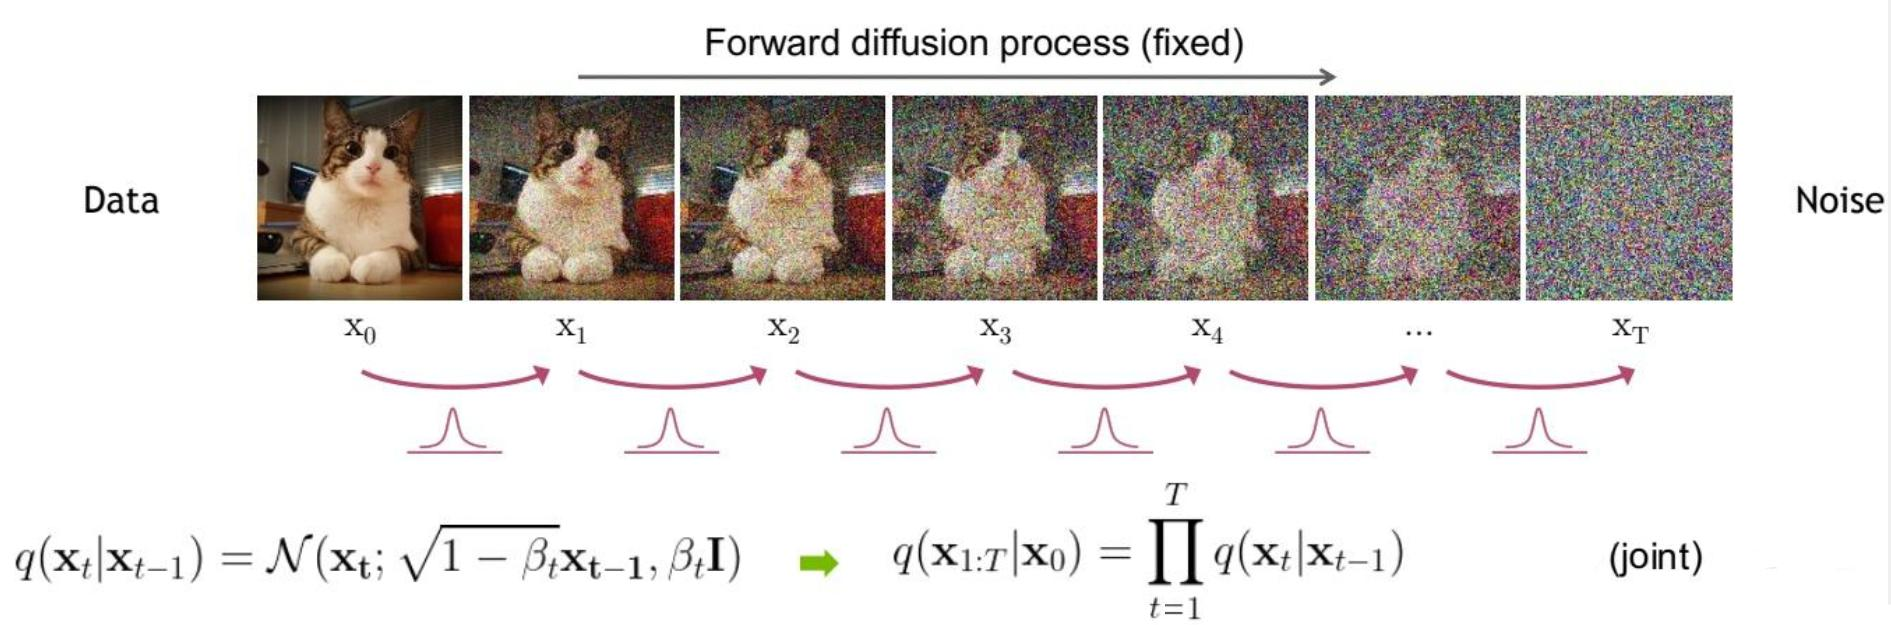

역방향 과정은 일반적으로 여러 단계의 노이즈 제거를 반복한다.

## 2. GAN과 Diffusion 모델 비교

| 구분            | GAN                       | Diffusion                    |
| ------------- | ------------------------- | ---------------------------- |
| 생성 원리         | 생성자와 판별자의 경쟁              | 점진적인 노이즈 제거                  |
| 주요 네트워크       | Generator + Discriminator | 노이즈 예측 신경망                   |
| 학습 방식         | 적대적 학습                    | 노이즈 예측 또는 관련 목적함수 최적화        |
| 이미지 생성        | 일반적으로 한 번의 생성자 실행         | 일반적으로 여러 단계의 반복              |
| 학습 안정성        | 적대적 학습으로 불안정할 수 있음        | 비교적 안정적인 학습이 가능              |
| Mode Collapse | 대표적인 문제 중 하나              | 전형적인 GAN식 Mode Collapse는 없음  |
| 생성 속도         | 대체로 빠름                    | 반복 단계 때문에 느릴 수 있음            |
| 대표 모델         | DCGAN, StyleGAN, BigGAN   | DDPM, DDIM, Stable Diffusion |

Diffusion 모델 역시 생성 품질이나 다양성에 문제가 발생할 수 있지만, GAN과 같은 두 신경망의 적대적 균형을 맞출 필요는 없다.

## 3. Diffusion 모델의 수학적 원리

### 3.1 Forward Diffusion

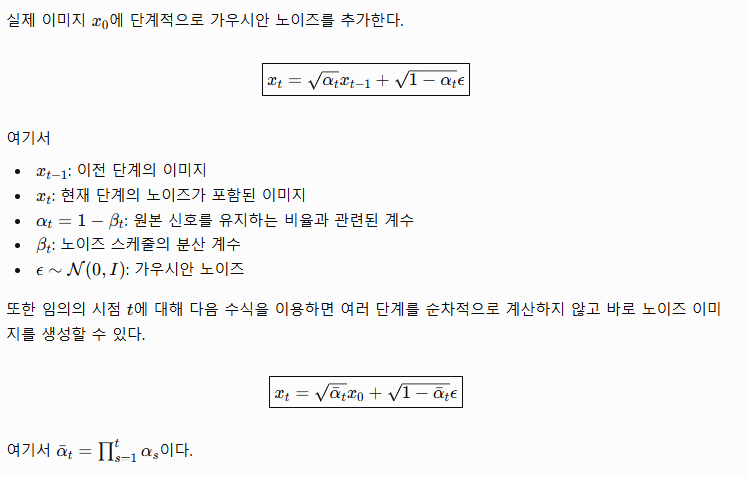

### 3.2 Reverse Diffusion

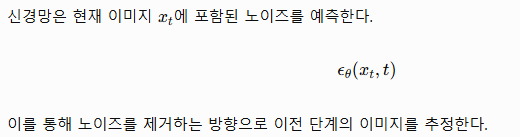

### 3.3 학습 손실함수

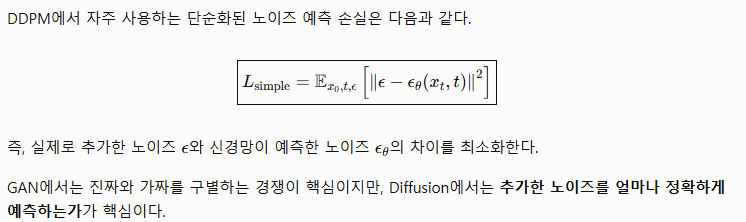



## 4. Diffusion 모델의 발전 과정

| 연도      | 모델                               | 주요 특징                       |
| ------- | -------------------------------- | --------------------------- |
| 2015    | 초기 Diffusion 확률 모델               | 확산 기반 생성 모델의 초기 연구          |
| 2020    | DDPM                             | 노이즈 예측 기반 생성 모델 발전          |
| 2020    | DDIM                             | 적은 샘플링 단계로 생성 가능            |
| 2021    | Improved DDPM                    | 학습 및 샘플링 개선                 |
| 2021    | Latent Diffusion 연구              | 잠재공간에서 확산 수행                |
| 2022    | Stable Diffusion                 | 잠재 확산 기반 텍스트-이미지 생성 확산      |
| 2023    | SDXL                             | 이미지 품질과 해상도 개선              |
| 2024 이후 | Diffusion Transformer·Flow 기반 모델 | Transformer 및 효율적인 생성 방식 확대 |


## 5. PyTorch 실습 — MNIST 이미지에 노이즈 추가

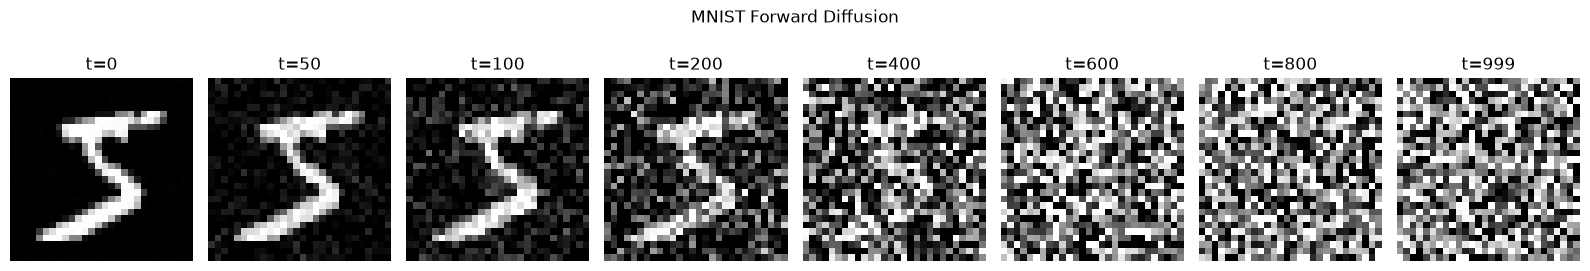

In [1]:
import torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

# CPU 또는 GPU 선택
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

# 확산 단계 수
T = 1000

# 노이즈 분산을 선형적으로 증가시킨다.
betas = torch.linspace(
    0.0001, 0.02, T, device=device
)

# 각 단계에서 원본 신호를 유지하는 계수이다.
alphas = 1.0 - betas

# 단계별 alpha의 누적 곱을 계산한다.
alpha_bars = torch.cumprod(alphas, dim=0)

# MNIST 이미지를 [-1, 1] 범위로 정규화한다.
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# MNIST 데이터셋을 불러온다.
dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# 첫 번째 이미지 선택
x0, label = dataset[0]

# 이미지에 배치 차원을 추가한다.
x0 = x0.unsqueeze(0).to(device)

# 임의의 단계 t에서 노이즈를 추가하는 함수이다.
def add_noise(x0, t):
    # 원본 이미지와 같은 형태의 가우시안 노이즈를 생성한다.
    noise = torch.randn_like(x0)

    # 현재 단계의 누적 alpha 값을 가져온다.
    alpha_bar = alpha_bars[t]

    # DDPM의 Forward Diffusion 수식을 적용한다.
    xt = (
        torch.sqrt(alpha_bar) * x0
        + torch.sqrt(1 - alpha_bar) * noise
    )

    return xt

# 서로 다른 확산 단계의 결과를 확인한다.
timesteps = [0, 50, 100, 200, 400, 600, 800, 999]

# 결과를 가로 방향으로 출력한다.
fig, axes = plt.subplots(1, len(timesteps), figsize=(16, 3))

for ax, t in zip(axes, timesteps):
    # 지정한 단계의 노이즈 이미지를 생성한다.
    xt = add_noise(x0, t)

    # 화면 표시를 위해 [-1, 1] 범위를 [0, 1]로 변환한다.
    image = ((xt[0, 0] + 1) / 2).clamp(0, 1)

    # 이미지를 출력한다.
    ax.imshow(image.cpu().numpy(), cmap="gray")
    ax.set_title(f"t={t}")
    ax.axis("off")

plt.suptitle("MNIST Forward Diffusion")
plt.tight_layout()
plt.show()


## 6. GAN 학습 이후 추천 실습 과정

앞서 학습한 GAN과 연결하여 다음 순서로 진행하면 모델 간 차이를 명확하게 이해할 수 있다.

1. Forward Diffusion: MNIST 이미지에 노이즈를 추가하고 단계별 변화 시각화
2. Noise Prediction: PyTorch CNN으로 노이즈 예측 모델 구현
3. DDPM: 역방향 노이즈 제거를 통해 MNIST 숫자 이미지 생성
4. Conditional DDPM: 숫자 0\~9를 지정하여 이미지 생성
5. U-Net: Skip Connection을 이용한 노이즈 예측 성능 개선
6. Diffusers: Hugging Face Diffusers 라이브러리를 이용한 생성 모델 실습
7. GAN vs DDPM: 생성 이미지 품질, 다양성, 학습 시간, 추론 시간 비교
8. FastAPI + STT + TTS: “숫자 7 이미지를 생성해 줘.”라는 음성 명령으로 조건부 Diffusion 이미지 생성

핵심: GAN은 판별자를 속이는 방향으로 Generator를 학습하지만, Diffusion 모델은 이미지에 추가된 노이즈를 예측하고 제거하는 방법을 학습한다. 이 차이가 두 생성 모델의 구조와 학습 방식을 구분하는 가장 중요한 기준이다.